<a href="https://colab.research.google.com/github/zack11112022/Tugas-probabilitas-stastika-Zakaria-Hutabarat/blob/main/Probabilitas_dan_Statistika_Zakaria_Hutabarat.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import re
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
from google.colab import files

In [3]:
up = files.upload()
nama_file = list(up.keys())[0]
print("File terbaca:", nama_file)

Saving Respons Gabungan 3 TI A - Versi Baru .xlsx to Respons Gabungan 3 TI A - Versi Baru .xlsx
File terbaca: Respons Gabungan 3 TI A - Versi Baru .xlsx


In [4]:
KELAS = "3 TI A"            # isi None untuk memakai semua kelas (uji coba)
JUMLAH_KOLOM_DEMOGRAFI = 6  # Timestamp, Score, Kelas, JK, Jml platform, Jml premium

df = pd.read_excel(nama_file)
df.columns = [str(c).strip() for c in df.columns]
df = df.dropna(axis=1, how="all")
if KELAS:
    df = df[df["Kelas"].astype(str).str.strip().str.upper() == KELAS.upper()]

# hanya kolom berformat "Dimensi [pernyataan]" (kolom Durasi tidak ikut)
kolom_butir = [c for c in df.columns[JUMLAH_KOLOM_DEMOGRAFI:] if re.match(r"^.*? \[.*\]$", c)]
butir = df[kolom_butir]

print("Jumlah responden :", len(df))
print("Jumlah butir     :", butir.shape[1])
print("Data kosong      :", int(butir.isna().sum().sum()))

Jumlah responden : 39
Jumlah butir     : 25
Data kosong      : 0


In [5]:
skala = {
    "Sangat Tidak Setuju (STS)": 1,
    "Tidak Setuju (TS)": 2,
    "Netral (N)": 3,
    "Setuju (S)": 4,
    "Sangat Setuju (SS)": 5,
}
num = butir.apply(lambda s: s.astype(str).str.strip().map(skala)).astype(float)

print("Sel yang gagal dikonversi:", int(num.isna().sum().sum()))  # harus 0
num.head()

Sel yang gagal dikonversi: 0


,Penggunaan AI pada tugas atau projek kuliah [AI5. Saya menggunakan AI untuk memperoleh contoh penyelesaian tugas kuliah.],Penggunaan AI pada tugas atau projek kuliah [AI6. Saya menggunakan AI untuk mengembangkan jawaban tugas kuliah.],Penggunaan AI pada tugas atau projek kuliah [AI7. Saya menggunakan AI untuk meninjau jawaban tugas kuliah sebelum dikumpulkan.],Aspek psikologis penggunaan AI pada tugas atau projek kuliah [PS1. Saya merasa membutuhkan bantuan AI untuk mulai mengerjakan tugas kuliah.],Aspek psikologis penggunaan AI pada tugas atau projek kuliah [PS2. Saya merasa perlu memperoleh saran AI sebelum menentukan langkah pengerjaan tugas kuliah.],Aspek psikologis penggunaan AI pada tugas atau projek kuliah [PS3. Saya merasa lebih yakin terhadap jawaban tugas setelah memperoleh konfirmasi dari AI.],Aspek psikologis penggunaan AI pada tugas atau projek kuliah [PS4. Saya merasa kesulitan melanjutkan pengerjaan tugas ketika bantuan AI terhenti.],Aspek psikologis penggunaan AI pada tugas atau projek kuliah [PS5. Saya merasa cemas ketika akses AI mengalami gangguan saat sedang mengerjakan tugas kuliah.],Aspek psikologis penggunaan AI pada tugas atau projek kuliah [PS6. Saya merasa dorongan untuk mengerjakan tugas bergantung pada ketersediaan bantuan AI.],Aspek psikologis penggunaan AI pada tugas atau projek kuliah [PS7. Saya merasa bergantung pada bantuan AI untuk menyelesaikan tugas kuliah.],...,Kebiasaan penggunaan teknologi digital [TD6. Saya menggunakan jawaban AI dalam tugas kuliah setelah membacanya sekilas.],Prokrastinasi akademik [PA1. Saya menunda memulai tugas kuliah hingga mendekati batas pengumpulan.],Prokrastinasi akademik [PA2. Saya memulai pengerjaan tugas kuliah lebih lambat daripada waktu yang saya rencanakan.],Prokrastinasi akademik [PA3. Saya menunda melanjutkan tugas kuliah yang sudah saya mulai.],Prokrastinasi akademik [PA4. Saya menyelesaikan tugas kuliah pada saat waktu pengumpulan hampir berakhir.],Respons emosional [RE1. Saya merasa tertekan ketika waktu pengerjaan tugas menjadi singkat akibat menunda.],Respons emosional [RE2. Saya merasa cemas ketika tugas yang saya tunda mendekati batas pengumpulan.],Respons emosional [RE3. Saya merasa panik ketika beberapa tugas yang saya tunda harus segera dikumpulkan.],Respons emosional [RE4. Saya merasa gelisah ketika memikirkan tugas yang pengerjaannya saya tunda.],Respons emosional [RE5. Saya merasa kewalahan menghadapi tugas yang menumpuk akibat penundaan.]
0,4.0,2.0,1.0,1.0,2.0,4.0,5.0,2.0,1.0,2.0,...,2.0,1.0,2.0,4.0,5.0,1.0,2.0,4.0,5.0,4.0
1,5.0,4.0,1.0,1.0,2.0,1.0,5.0,5.0,4.0,5.0,...,1.0,4.0,4.0,4.0,1.0,5.0,1.0,1.0,5.0,4.0
2,2.0,2.0,1.0,2.0,2.0,1.0,2.0,1.0,2.0,1.0,...,2.0,1.0,2.0,2.0,1.0,1.0,2.0,2.0,1.0,2.0
3,2.0,4.0,5.0,1.0,2.0,4.0,5.0,2.0,1.0,4.0,...,5.0,1.0,2.0,5.0,4.0,1.0,2.0,4.0,5.0,4.0
4,2.0,4.0,5.0,5.0,4.0,2.0,1.0,2.0,3.0,4.0,...,4.0,5.0,4.0,2.0,1.0,5.0,4.0,2.0,1.0,2.0


In [6]:
KOREKSI = {"Rsspon emosional": "Respon emosional",
           "Prokrastinasi akademik.": "Prokrastinasi akademik"}

dimensi = {}
for kolom in butir.columns:
    nama = re.match(r"^(.*?) \[", kolom).group(1).strip()
    nama = KOREKSI.get(nama, nama)
    dimensi.setdefault(nama, []).append(kolom)

for nama, daftar in dimensi.items():
    print(f"{nama}: {len(daftar)} butir")

Penggunaan AI pada tugas atau projek kuliah: 3 butir
Aspek psikologis penggunaan AI pada tugas atau projek kuliah: 7 butir
Kebiasaan penggunaan teknologi digital: 6 butir
Prokrastinasi akademik: 4 butir
Respons emosional: 5 butir


In [7]:
n = len(num)
t = stats.t.ppf(0.975, n - 2)
r_tabel = t / np.sqrt((n - 2) + t**2)
print(f"n = {n} | r tabel (α=0,05; df={n-2}) = {r_tabel:.3f}")

hasil_validitas = []
for nama, daftar in dimensi.items():
    x = num[daftar]
    total = x.sum(axis=1)
    for i, kolom in enumerate(daftar, 1):
        r, p = stats.pearsonr(x[kolom], total)
        r_koreksi, _ = stats.pearsonr(x[kolom], total - x[kolom])
        hasil_validitas.append({
            "Dimensi": nama,
            "Butir": f"B{i}",
            "r hitung": round(r, 3),
            "Corrected r": round(r_koreksi, 3),
            "p-value": round(p, 4),
            "Keterangan": "Valid" if r > r_tabel else "Tidak valid",
        })

tabel_validitas = pd.DataFrame(hasil_validitas)
tabel_validitas

n = 39 | r tabel (α=0,05; df=37) = 0.316


,Dimensi,Butir,r hitung,Corrected r,p-value,Keterangan
0,Penggunaan AI pada tugas atau projek kuliah,B1,0.659,0.193,0.0000,Valid
1,Penggunaan AI pada tugas atau projek kuliah,B2,0.540,0.123,0.0004,Valid
2,Penggunaan AI pada tugas atau projek kuliah,B3,0.789,0.372,0.0000,Valid
3,Aspek psikologis penggunaan AI pada tugas atau...,B1,0.494,0.150,0.0014,Valid
4,Aspek psikologis penggunaan AI pada tugas atau...,B2,0.559,0.311,0.0002,Valid
5,Aspek psikologis penggunaan AI pada tugas atau...,B3,0.569,0.340,0.0002,Valid
6,Aspek psikologis penggunaan AI pada tugas atau...,B4,0.256,-0.062,0.1157,Tidak valid
7,Aspek psikologis penggunaan AI pada tugas atau...,B5,0.422,0.137,0.0075,Valid
8,Aspek psikologis penggunaan AI pada tugas atau...,B6,0.560,0.299,0.0002,Valid
9,Aspek psikologis penggunaan AI pada tugas atau...,B7,0.484,0.236,0.0018,Valid


In [8]:
def cronbach_alpha(x):
    k = x.shape[1]
    return k / (k - 1) * (1 - x.var(ddof=1).sum() / x.sum(axis=1).var(ddof=1))

def kategori(a):
    return ("Sangat baik" if a >= 0.90 else "Baik" if a >= 0.80
            else "Reliabel" if a >= 0.70 else "Tidak reliabel")

hasil_reliabilitas = []
alpha_dihapus = []

for nama, daftar in dimensi.items():
    x = num[daftar]
    a = cronbach_alpha(x)
    hasil_reliabilitas.append({
        "Dimensi": nama,
        "Jumlah butir": len(daftar),
        "Cronbach's alpha": round(a, 3),
        "Kategori": kategori(a),
    })
    for i, kolom in enumerate(daftar, 1):
        if len(daftar) > 2:
            alpha_dihapus.append({
                "Dimensi": nama,
                "Butir": f"B{i}",
                "Alpha jika dihapus": round(cronbach_alpha(x.drop(columns=kolom)), 3),
            })

tabel_reliabilitas = pd.DataFrame(hasil_reliabilitas)
tabel_alpha_dihapus = pd.DataFrame(alpha_dihapus)
display(tabel_reliabilitas)
display(tabel_alpha_dihapus)

,Dimensi,Jumlah butir,Cronbach's alpha,Kategori
0,Penggunaan AI pada tugas atau projek kuliah,3,0.382,Tidak reliabel
1,Aspek psikologis penggunaan AI pada tugas atau...,7,0.421,Tidak reliabel
2,Kebiasaan penggunaan teknologi digital,6,0.308,Tidak reliabel
3,Prokrastinasi akademik,4,0.111,Tidak reliabel
4,Respons emosional,5,0.516,Tidak reliabel


,Dimensi,Butir,Alpha jika dihapus
0,Penggunaan AI pada tugas atau projek kuliah,B1,0.353
1,Penggunaan AI pada tugas atau projek kuliah,B2,0.455
2,Penggunaan AI pada tugas atau projek kuliah,B3,-0.059
3,Aspek psikologis penggunaan AI pada tugas atau...,B1,0.412
4,Aspek psikologis penggunaan AI pada tugas atau...,B2,0.322
5,Aspek psikologis penggunaan AI pada tugas atau...,B3,0.312
6,Aspek psikologis penggunaan AI pada tugas atau...,B4,0.509
7,Aspek psikologis penggunaan AI pada tugas atau...,B5,0.410
8,Aspek psikologis penggunaan AI pada tugas atau...,B6,0.326
9,Aspek psikologis penggunaan AI pada tugas atau...,B7,0.363


In [9]:
gabung = tabel_validitas.merge(tabel_alpha_dihapus, on=["Dimensi", "Butir"], how="left")
alpha_dim = tabel_reliabilitas.set_index("Dimensi")["Cronbach's alpha"]

def keputusan(b):
    valid = b["Keterangan"] == "Valid"
    naik = b["Alpha jika dihapus"] > alpha_dim[b["Dimensi"]]
    if valid and not naik: return "Pertahankan"
    if valid and naik:     return "Tinjau isi butir (ambigu/beda konstruk)"
    if not valid and naik: return "Buang atau revisi, lalu uji ulang"
    return "Tinjau ulang sebelum dibuang"

gabung["Keputusan"] = gabung.apply(keputusan, axis=1)

with pd.ExcelWriter("hasil_uji_validitas_reliabilitas.xlsx") as w:
    gabung.to_excel(w, sheet_name="Validitas", index=False)
    tabel_reliabilitas.to_excel(w, sheet_name="Reliabilitas", index=False)

files.download("hasil_uji_validitas_reliabilitas.xlsx")
gabung[["Dimensi", "Butir", "r hitung", "Alpha jika dihapus", "Keterangan", "Keputusan"]]

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

,Dimensi,Butir,r hitung,Alpha jika dihapus,Keterangan,Keputusan
0,Penggunaan AI pada tugas atau projek kuliah,B1,0.659,0.353,Valid,Pertahankan
1,Penggunaan AI pada tugas atau projek kuliah,B2,0.540,0.455,Valid,Tinjau isi butir (ambigu/beda konstruk)
2,Penggunaan AI pada tugas atau projek kuliah,B3,0.789,-0.059,Valid,Pertahankan
3,Aspek psikologis penggunaan AI pada tugas atau...,B1,0.494,0.412,Valid,Pertahankan
4,Aspek psikologis penggunaan AI pada tugas atau...,B2,0.559,0.322,Valid,Pertahankan
5,Aspek psikologis penggunaan AI pada tugas atau...,B3,0.569,0.312,Valid,Pertahankan
6,Aspek psikologis penggunaan AI pada tugas atau...,B4,0.256,0.509,Tidak valid,"Buang atau revisi, lalu uji ulang"
7,Aspek psikologis penggunaan AI pada tugas atau...,B5,0.422,0.410,Valid,Pertahankan
8,Aspek psikologis penggunaan AI pada tugas atau...,B6,0.560,0.326,Valid,Pertahankan
9,Aspek psikologis penggunaan AI pada tugas atau...,B7,0.484,0.363,Valid,Pertahankan


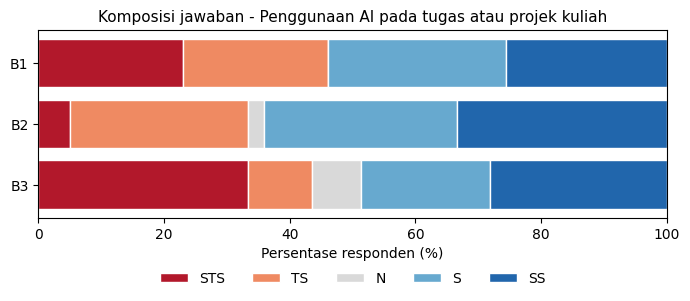

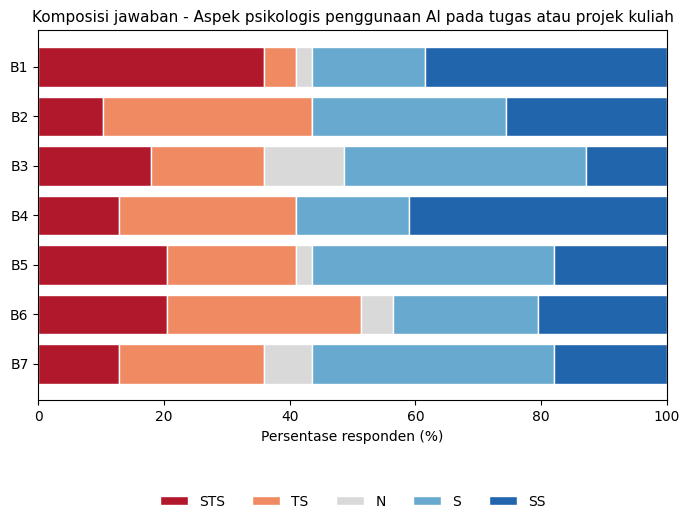

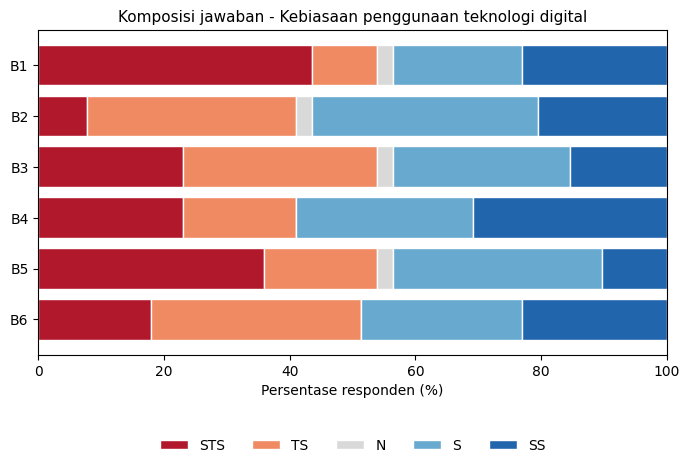

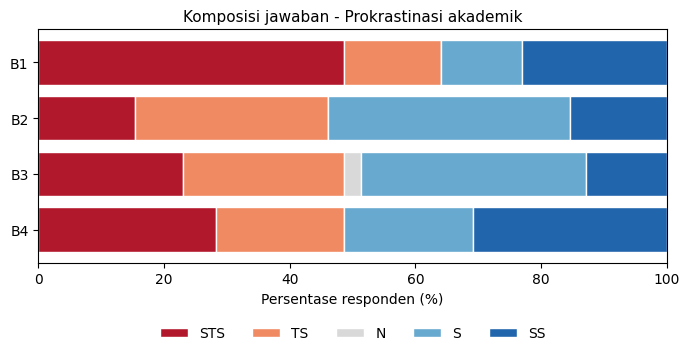

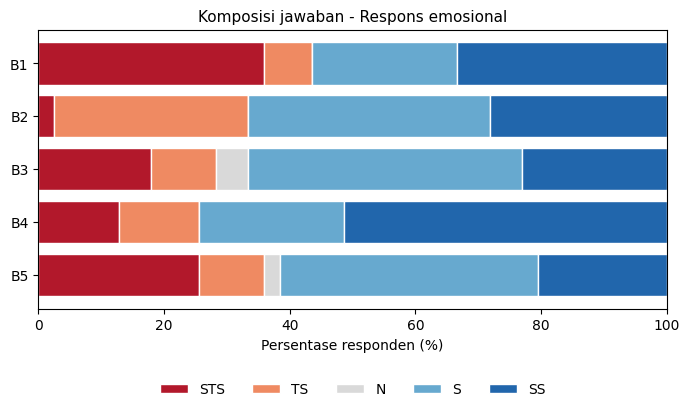

,Dimensi,Mean total,SD,Skewness,Kurtosis
0,Penggunaan AI pada tugas atau projek kuliah,9.69,3.105,-0.108,-1.209
1,Aspek psikologis penggunaan AI pada tugas atau...,22.33,4.975,0.339,-0.277
2,Kebiasaan penggunaan teknologi digital,17.72,4.353,-0.109,0.986
3,Prokrastinasi akademik,11.49,3.276,-0.075,0.354
4,Respons emosional,17.21,4.408,0.019,-0.973


In [10]:
label = {1: "STS", 2: "TS", 3: "N", 4: "S", 5: "SS"}
warna = ["#b2182b", "#ef8a62", "#d9d9d9", "#67a9cf", "#2166ac"]
deskriptif = []

for nama, daftar in dimensi.items():
    kodes = [f"B{i}" for i in range(1, len(daftar) + 1)]
    pct = pd.DataFrame({k: num[c].value_counts(normalize=True).reindex([1,2,3,4,5]).fillna(0) * 100
                        for k, c in zip(kodes, daftar)}).T
    fig, ax = plt.subplots(figsize=(7, 0.55 * len(kodes) + 1.6))
    left = np.zeros(len(kodes))
    for v, w in zip([1,2,3,4,5], warna):
        ax.barh(kodes, pct[v], left=left, color=w, label=label[v], edgecolor="white")
        left += pct[v].values
    ax.invert_yaxis(); ax.set_xlim(0, 100); ax.set_xlabel("Persentase responden (%)")
    ax.set_title(f"Komposisi jawaban - {nama}", fontsize=11)
    ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.22), frameon=False)
    fig.tight_layout()
    nama_file_gambar = "komposisi_" + re.sub(r"\W+", "_", nama) + ".png"
    fig.savefig(nama_file_gambar, dpi=200)
    plt.show()

    tot = num[daftar].sum(axis=1)
    deskriptif.append({"Dimensi": nama, "Mean total": round(tot.mean(), 2),
                       "SD": round(tot.std(ddof=1), 3),
                       "Skewness": round(stats.skew(tot, bias=False), 3),
                       "Kurtosis": round(stats.kurtosis(tot, bias=False), 3)})

pd.DataFrame(deskriptif)

In [11]:
# Latihan 2: perbandingan kriteria
print("Valid (r hitung > r tabel)  :", (tabel_validitas["r hitung"] > r_tabel).sum(), "dari", len(tabel_validitas))
print("Valid (corrected r >= 0,30) :", (tabel_validitas["Corrected r"] >= 0.30).sum(), "dari", len(tabel_validitas))

# Latihan 3: buang satu butir, bandingkan alpha (ubah dua baris ini)
dimensi_uji = list(dimensi.keys())[0]
butir_dibuang = dimensi[dimensi_uji][0]
sebelum = cronbach_alpha(num[dimensi[dimensi_uji]])
sesudah = cronbach_alpha(num[dimensi[dimensi_uji]].drop(columns=butir_dibuang))
print(f"{dimensi_uji}: α sebelum = {sebelum:.3f} | sesudah = {sesudah:.3f}")

# Latihan 4: pengaruh ukuran sampel
m = min(20, len(num))
sub = num.sample(m, random_state=1)
t2 = stats.t.ppf(0.975, m - 2)
r_tabel2 = t2 / np.sqrt((m - 2) + t2**2)
jumlah_valid = 0
for nama, daftar in dimensi.items():
    x = sub[daftar]; total = x.sum(axis=1)
    for kolom in daftar:
        r, _ = stats.pearsonr(x[kolom], total)
        jumlah_valid += int(r > r_tabel2)
print(f"n = {m} | r tabel = {r_tabel2:.3f} | butir valid = {jumlah_valid} dari {num.shape[1]}")

Valid (r hitung > r tabel)  : 23 dari 25
Valid (corrected r >= 0,30) : 7 dari 25
Penggunaan AI pada tugas atau projek kuliah: α sebelum = 0.382 | sesudah = 0.353
n = 20 | r tabel = 0.444 | butir valid = 18 dari 25
